# Finite-rate conversion and the postmerger GW peak frequency

**Model.** The converted fraction of the critical-pressure region at postmerger time $\Delta t_{\rm pm}$ is

$$X_q(u,\Delta t_{\rm pm}) = \min\{1, [u\,\Delta t_{\rm pm}/R_{\rm crit}]^2\},$$

and the finite-rate peak frequency is the phenomenological interpolation

$$f_{\rm peak}^{\rm finite} = f_{\rm peak}^{N} + X_q\,\Delta f_{\rm PT}
= f_{\rm peak}^{\infty} - (1-X_q)\,\Delta f_{\rm PT},
\qquad \Delta f_{\rm PT} = f_{\rm peak}^{\infty} - f_{\rm peak}^{N}.$$

Here $f_{\rm peak}^{N}$ is the peak with no quark-matter conversion, $f_{\rm peak}^{\infty}$ the
equilibrium (instantaneous-conversion) result, $u$ the phase-boundary speed, and
$R_{\rm crit}$ the characteristic conversion-region size. The saturation velocity is
$u_{\rm sat} = R_{\rm crit}/\Delta t_{\rm pm}$. The finite-rate frequency deficit is
$\delta f_{\rm rate} = f_{\rm peak}^{\infty} - f_{\rm peak}^{\rm finite} = (1-X_q)\,\Delta f_{\rm PT}$.

**Simulation-calibrated cases** (endpoint frequencies in kHz):

| # | Source | EOS pair | Masses | $f_{\rm peak}^{N}$ | $f_{\rm peak}^{\infty}$ | $\Delta f_{\rm PT}$ |
|---|--------|----------|--------|------|------|------|
| 1 | Prakash et al. | BLh/BLQ | 1.298+1.298 | 2.804 | 2.927 | 0.123 |
| 2 | Prakash et al. | BLh/BLQ | 1.481+1.257 | 2.962 | 3.143 | 0.181 |
| 3 | Prakash et al. | BLh/BLQ | 1.398+1.198 | 2.758 | 2.955 | 0.197 |
| 4 | Prakash et al. | BLh/BLQ | 1.363+1.363 | 3.074 | 3.197 | 0.123 |
| 5 | Prakash et al. | DD2F/DD2F-SF1 | 1.289+1.289 | 2.889 | 3.354 | 0.465 |
| 6 | Bauswein et al. | DD2F/DD2F-SF1 | 1.35+1.35 | 3.098 | 3.540 | 0.442 |
| 7 | Bauswein et al. | DD2F/DD2F-SF1 | q = 0.8 | 3.010 | 3.790 | 0.780 |

**Scientific discussion — read before using these numbers.**

1. The quoted $\Delta f_{\rm PT}$ values are *endpoint calibrations* from equilibrium
   hybrid-EOS merger simulations: each is the difference between two separate runs
   (purely hadronic EOS vs. hybrid EOS with an equilibrium phase transition).
2. Those simulations do **not** explicitly evolve a finite-speed conversion front;
   they bracket the finite-rate outcome but contain no information about intermediate $X_q$.
3. The relation $f_{\rm peak}^{\rm finite} = f_{\rm peak}^{N} + X_q\,\Delta f_{\rm PT}$ is a
   phenomenological interpolation that remains to be tested with finite-rate
   numerical-relativity simulations.
4. $\Delta f_{\rm PT}$ is not universal: it depends on the EOS pair, the transition strength,
   the binary masses, and the mass ratio (compare cases 1-4 with 5-7).
5. If conversion occurs *during* the analyzed postmerger interval, the spectrum may show
   separate nuclear and quark peaks rather than one continuously interpolated peak;
   the single-$f_{\rm peak}$ description then breaks down.

Note on geometry: the drop-in paper section (`Latex_drop_in_integrated/v2/`) uses the
two-lobed (taiji) geometry with cubic exponent, $X_q = \min\{1,[u\,\Delta t_{\rm pm}/R_{\rm lobe}]^3\}$.
This study follows the quadratic single-region model specified above; switch with
`MODEL_EXPONENT` in the setup cell.

**References**: Prakash et al., [arXiv:2310.06025](https://arxiv.org/abs/2310.06025);
Bauswein et al., [arXiv:1809.01116](https://arxiv.org/abs/1809.01116);
Weih et al., [arXiv:1912.09340](https://arxiv.org/abs/1912.09340).


In [1]:
# Tunable model parameters and numerical table
DT_PM_MS = 10.0           # postmerger evaluation time Delta_t_pm [ms]
R_CRIT_KM = 10.0          # conversion-region size R_crit [km]
MODEL_EXPONENT = 2        # 2 = quadratic single-region model (this study);
                          # 3 = two-lobed taiji geometry of the paper section
U_GRID_KM_S = None        # set below: log grid in km/s
U_GRID_RANGE = (1.0e-1, 1.0e4)
U_GRID_POINTS = 401
TABLE_U_KM_S = [0.1, 0.3, 1.0, 3.0, 10.0, 100.0, 300.0, 1000.0, 3000.0]
EXPORT_DIR = "figs"
TABLE_PATH = "figs/finite_rate_fpeak_table.csv"

import os
import numpy as np
import pandas as pd

os.makedirs(EXPORT_DIR, exist_ok=True)

U_SAT_KM_S = R_CRIT_KM / (DT_PM_MS * 1.0e-3)
print(f"u_sat = R_crit/Delta_t_pm = {U_SAT_KM_S:.0f} km/s")

# (source, EOS pair, masses, f_peak_N [kHz], f_peak_inf [kHz])
CASES = [
    ("Prakash+", "BLh/BLQ", "1.298+1.298", 2.804, 2.927),
    ("Prakash+", "BLh/BLQ", "1.481+1.257", 2.962, 3.143),
    ("Prakash+", "BLh/BLQ", "1.398+1.198", 2.758, 2.955),
    ("Prakash+", "BLh/BLQ", "1.363+1.363", 3.074, 3.197),
    ("Prakash+", "DD2F/DD2F-SF1", "1.289+1.289", 2.889, 3.354),
    ("Bauswein+", "DD2F/DD2F-SF1", "1.35+1.35", 3.098, 3.540),
    ("Bauswein+", "DD2F/DD2F-SF1", "q=0.8", 3.010, 3.790),
]

# Fixed categorical assignment (validated colorblind-safe set + black), never cycled
CASE_COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00", "#000000"]
CASE_STYLES = ["-", "--", "-.", ":", "-", "--", "-."]

def X_q_of_u(u_km_s, dt_pm_ms=DT_PM_MS, r_crit_km=R_CRIT_KM, exponent=MODEL_EXPONENT):
    """Converted fraction X_q(u); u in km/s, dt in ms, R in km."""
    swept_km = np.asarray(u_km_s) * dt_pm_ms * 1.0e-3
    return np.minimum(1.0, (swept_km / r_crit_km) ** exponent)

def f_finite_kHz(u_km_s, f_N, f_inf, **kw):
    return f_N + X_q_of_u(u_km_s, **kw) * (f_inf - f_N)

def case_label(src, eos, masses, f_N, f_inf):
    return f"{src} {eos} {masses} ($\\Delta f_{{\\rm PT}}$={f_inf - f_N:.3f} kHz)"

U_GRID_KM_S = np.logspace(np.log10(U_GRID_RANGE[0]), np.log10(U_GRID_RANGE[1]), U_GRID_POINTS)

rows = []
for src, eos, masses, f_N, f_inf in CASES:
    for u in TABLE_U_KM_S + [U_SAT_KM_S]:
        xq = float(X_q_of_u(u))
        ff = f_N + xq * (f_inf - f_N)
        rows.append({
            "source": src, "EOS_pair": eos, "masses": masses,
            "f_peak_N_kHz": f_N, "f_peak_inf_kHz": f_inf,
            "Delta_f_PT_kHz": round(f_inf - f_N, 3),
            "u_km_s": u, "X_q": xq,
            "f_peak_finite_kHz": ff,
            "delta_f_rate_kHz": f_inf - ff,
        })
table = pd.DataFrame(rows).sort_values(["Delta_f_PT_kHz", "u_km_s"]).reset_index(drop=True)
table.to_csv(TABLE_PATH, index=False)
print(f"wrote {TABLE_PATH} ({len(table)} rows)")
table[table["masses"] == "q=0.8"].round(6)


u_sat = R_crit/Delta_t_pm = 1000 km/s
wrote figs/finite_rate_fpeak_table.csv (70 rows)


,source,EOS_pair,masses,f_peak_N_kHz,f_peak_inf_kHz,Delta_f_PT_kHz,u_km_s,X_q,f_peak_finite_kHz,delta_f_rate_kHz
60,Bauswein+,DD2F/DD2F-SF1,q=0.8,3.01,3.79,0.78,0.1,0.000000,3.010000,0.780000
61,Bauswein+,DD2F/DD2F-SF1,q=0.8,3.01,3.79,0.78,0.3,0.000000,3.010000,0.780000
62,Bauswein+,DD2F/DD2F-SF1,q=0.8,3.01,3.79,0.78,1.0,0.000001,3.010001,0.779999
63,Bauswein+,DD2F/DD2F-SF1,q=0.8,3.01,3.79,0.78,3.0,0.000009,3.010007,0.779993
64,Bauswein+,DD2F/DD2F-SF1,q=0.8,3.01,3.79,0.78,10.0,0.000100,3.010078,0.779922
65,Bauswein+,DD2F/DD2F-SF1,q=0.8,3.01,3.79,0.78,100.0,0.010000,3.017800,0.772200
66,Bauswein+,DD2F/DD2F-SF1,q=0.8,3.01,3.79,0.78,300.0,0.090000,3.080200,0.709800
67,Bauswein+,DD2F/DD2F-SF1,q=0.8,3.01,3.79,0.78,1000.0,1.000000,3.790000,0.000000
68,Bauswein+,DD2F/DD2F-SF1,q=0.8,3.01,3.79,0.78,1000.0,1.000000,3.790000,0.000000
69,Bauswein+,DD2F/DD2F-SF1,q=0.8,3.01,3.79,0.78,3000.0,1.000000,3.790000,0.000000


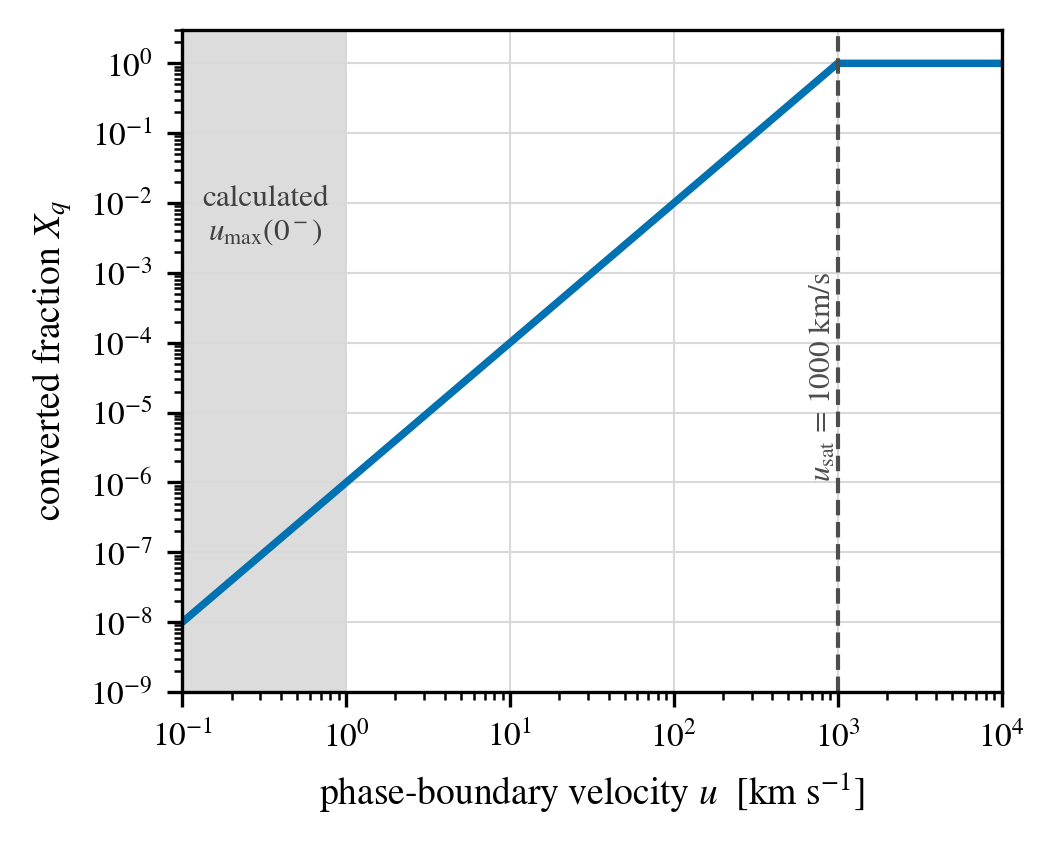

wrote figs/fig1_Xq_vs_u.pdf/.png


In [2]:
# Tunable plotting parameters
FIGURE_SIZE = (3.4, 2.7)
DPI = 300
FONT_FAMILY = "STIXGeneral"
MATH_FONTSET = "stix"
AXIS_LABEL_FONT_SIZE = 9
TICK_LABEL_FONT_SIZE = 8
ANNOTATION_FONT_SIZE = 7.5
LINE_WIDTH = 1.8
CURVE_COLOR = "#0072B2"
VLINE_COLOR = "0.3"
VLINE_STYLE = "--"
VLINE_WIDTH = 1.0
BAND_COLOR = "0.55"
BAND_ALPHA = 0.30
U_MAX_BAND_KM_S = (0.1, 1.0)   # calculated weak-limited boundary speeds
GRID_COLOR = "0.85"
GRID_LINE_WIDTH = 0.5
X_LIMITS = (1.0e-1, 1.0e4)
Y_LIMITS = (1.0e-9, 3.0)
X_SCALE = "log"
Y_SCALE = "log"
EXPORT_STEM = "figs/fig1_Xq_vs_u"

# Figure 1: converted fraction X_q(u) with saturation velocity u_sat
import matplotlib.pyplot as plt

RC = {"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET,
      "axes.labelsize": AXIS_LABEL_FONT_SIZE, "xtick.labelsize": TICK_LABEL_FONT_SIZE,
      "ytick.labelsize": TICK_LABEL_FONT_SIZE}

with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=DPI)
    ax.plot(U_GRID_KM_S, X_q_of_u(U_GRID_KM_S), CURVE_COLOR and "-", color=CURVE_COLOR, lw=LINE_WIDTH)
    ax.axvline(U_SAT_KM_S, color=VLINE_COLOR, ls=VLINE_STYLE, lw=VLINE_WIDTH)
    ax.annotate(f"$u_{{\\rm sat}}$ = {U_SAT_KM_S:.0f} km/s", xy=(U_SAT_KM_S, 1e-6),
                rotation=90, ha="right", va="bottom", fontsize=ANNOTATION_FONT_SIZE, color=VLINE_COLOR)
    ax.axvspan(*U_MAX_BAND_KM_S, color=BAND_COLOR, alpha=BAND_ALPHA, lw=0)
    ax.annotate("calculated\n$u_{\\rm max}(0^-)$", xy=(0.32, 3e-3), ha="center",
                fontsize=ANNOTATION_FONT_SIZE, color="0.25")
    ax.set_xscale(X_SCALE); ax.set_yscale(Y_SCALE)
    ax.set_xlim(*X_LIMITS); ax.set_ylim(*Y_LIMITS)
    ax.set_xlabel(r"phase-boundary velocity $u$  [km s$^{-1}$]")
    ax.set_ylabel(r"converted fraction $X_q$")
    ax.grid(True, which="major", color=GRID_COLOR, lw=GRID_LINE_WIDTH)
    fig.tight_layout(pad=0.3)
    fig.savefig(EXPORT_STEM + ".pdf"); fig.savefig(EXPORT_STEM + ".png")
    plt.show()
print(f"wrote {EXPORT_STEM}.pdf/.png")


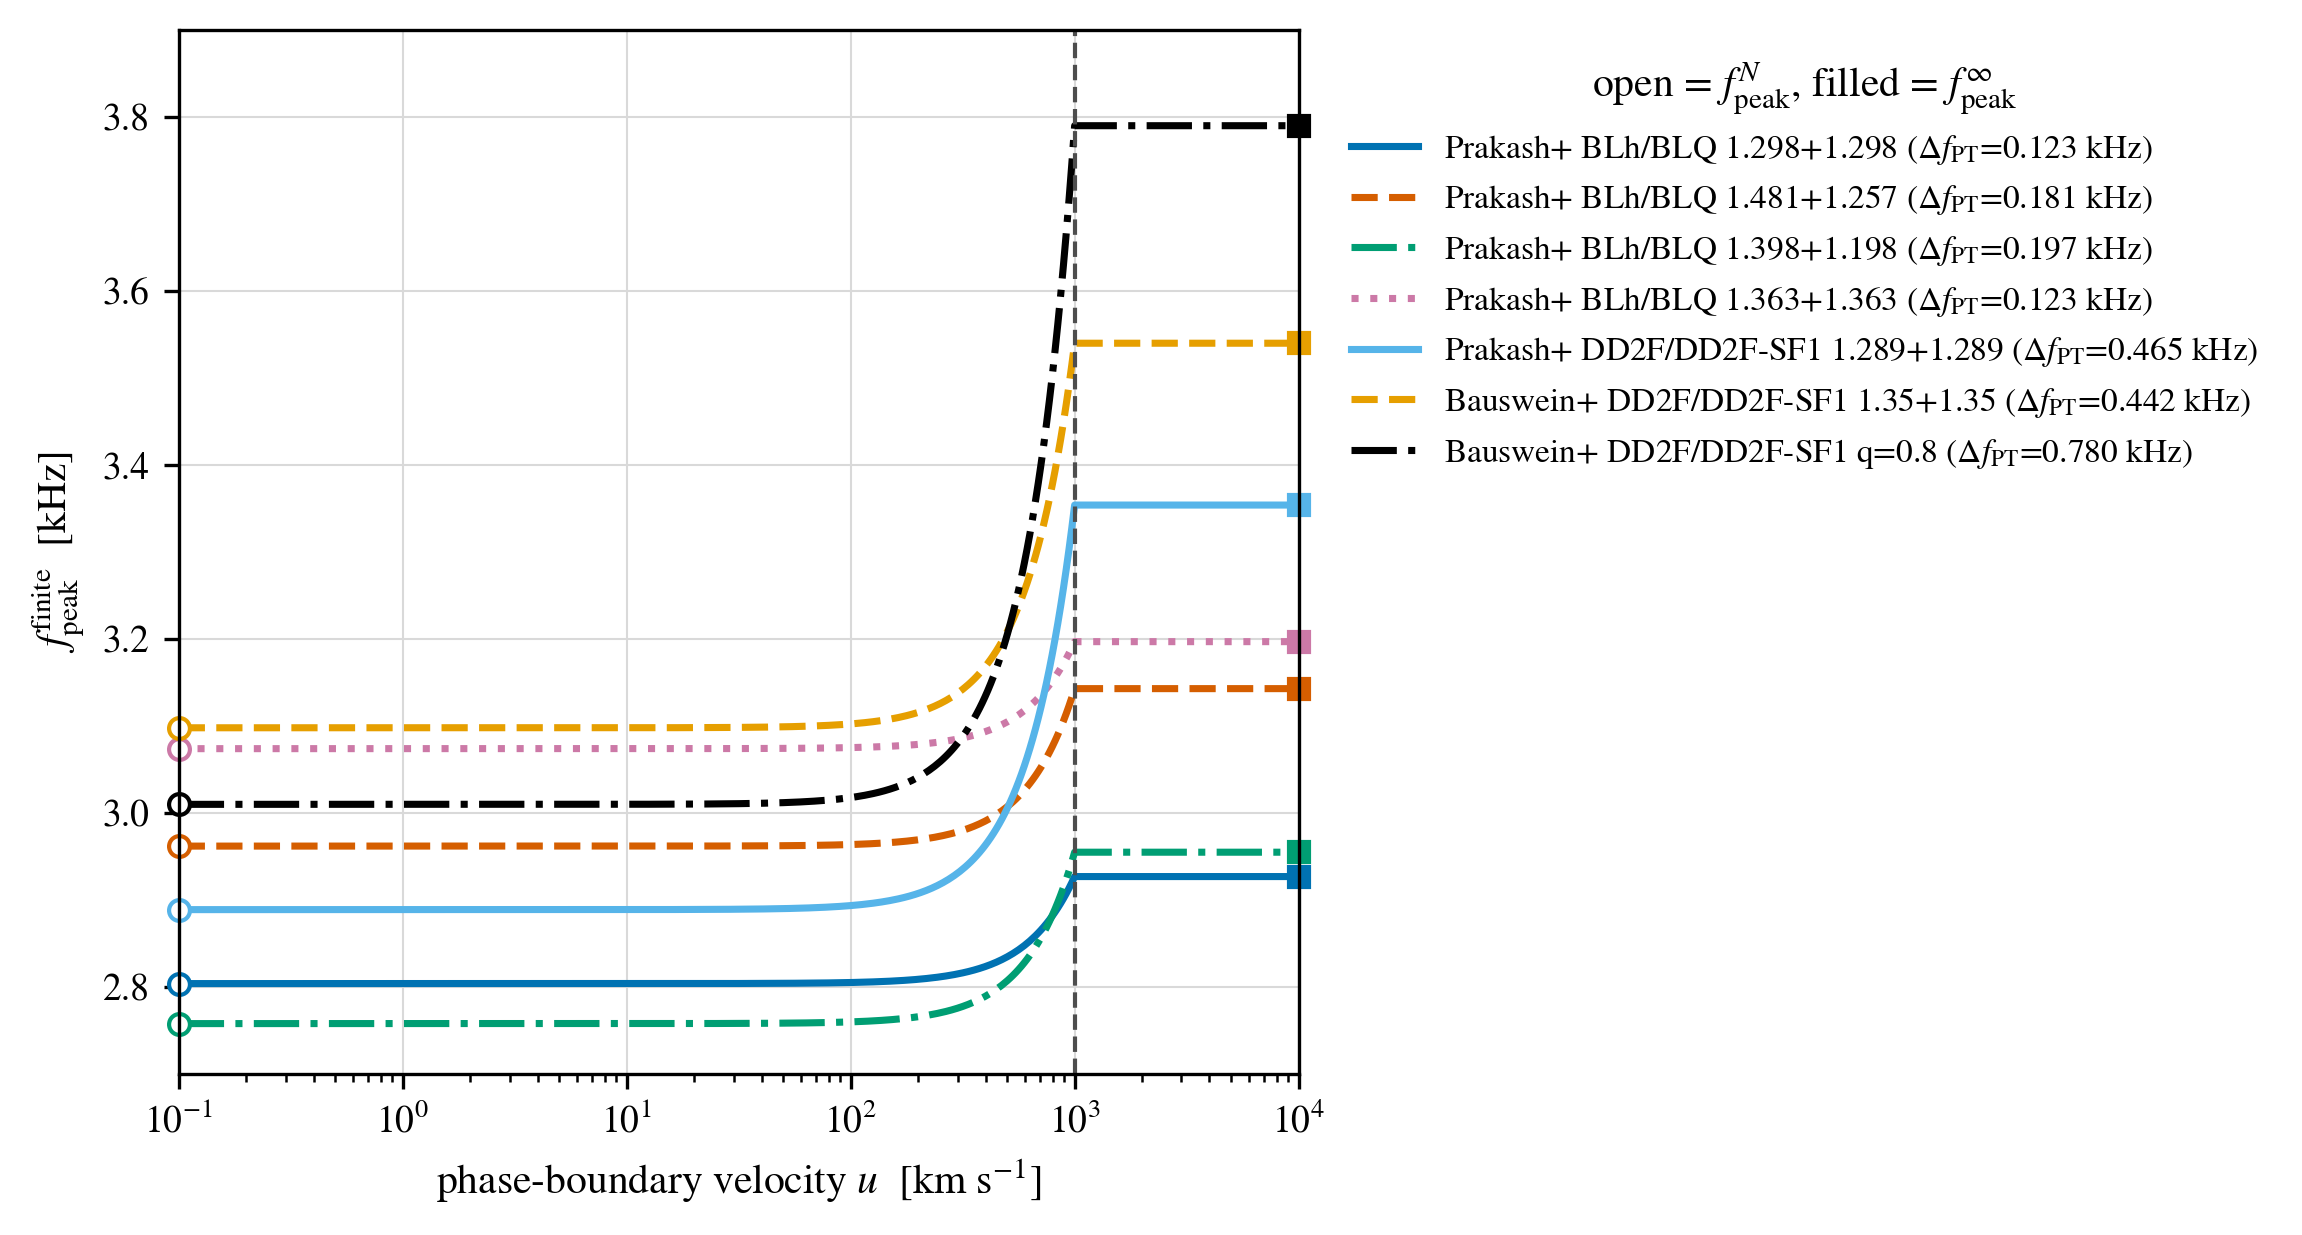

wrote figs/fig2_fpeak_finite_vs_u.pdf/.png


In [3]:
# Tunable plotting parameters
FIGURE_SIZE = (7.6, 4.0)
DPI = 300
FONT_FAMILY = "STIXGeneral"
MATH_FONTSET = "stix"
AXIS_LABEL_FONT_SIZE = 10
TICK_LABEL_FONT_SIZE = 9
LEGEND_FONT_SIZE = 8
LINE_WIDTH = 1.7
MARKER_SIZE = 5
START_MARKER = "o"        # open marker at f_peak_N (u -> 0)
END_MARKER = "s"          # filled marker at f_peak_inf (u >> u_sat)
VLINE_COLOR = "0.3"
VLINE_STYLE = "--"
VLINE_WIDTH = 1.0
GRID_COLOR = "0.85"
GRID_LINE_WIDTH = 0.5
X_LIMITS = (1.0e-1, 1.0e4)
Y_LIMITS = (2.70, 3.90)
X_SCALE = "log"
LEGEND_ANCHOR = (1.02, 1.0)
LEGEND_LOCATION = "upper left"
EXPORT_STEM = "figs/fig2_fpeak_finite_vs_u"

# Figure 2: finite-rate peak frequency for the seven simulation-calibrated cases
import matplotlib.pyplot as plt

RC = {"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET,
      "axes.labelsize": AXIS_LABEL_FONT_SIZE, "xtick.labelsize": TICK_LABEL_FONT_SIZE,
      "ytick.labelsize": TICK_LABEL_FONT_SIZE, "legend.fontsize": LEGEND_FONT_SIZE}

with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=DPI)
    for (src, eos, masses, f_N, f_inf), color, style in zip(CASES, CASE_COLORS, CASE_STYLES):
        ax.plot(U_GRID_KM_S, f_finite_kHz(U_GRID_KM_S, f_N, f_inf), style, color=color,
                lw=LINE_WIDTH, label=case_label(src, eos, masses, f_N, f_inf))
        ax.plot(X_LIMITS[0], f_N, START_MARKER, color=color, ms=MARKER_SIZE,
                mfc="white", clip_on=False)
        ax.plot(X_LIMITS[1], f_inf, END_MARKER, color=color, ms=MARKER_SIZE, clip_on=False)
    ax.axvline(U_SAT_KM_S, color=VLINE_COLOR, ls=VLINE_STYLE, lw=VLINE_WIDTH)
    ax.set_xscale(X_SCALE)
    ax.set_xlim(*X_LIMITS); ax.set_ylim(*Y_LIMITS)
    ax.set_xlabel(r"phase-boundary velocity $u$  [km s$^{-1}$]")
    ax.set_ylabel(r"$f_{\rm peak}^{\rm finite}$  [kHz]")
    ax.grid(True, which="major", color=GRID_COLOR, lw=GRID_LINE_WIDTH)
    ax.legend(loc=LEGEND_LOCATION, bbox_to_anchor=LEGEND_ANCHOR, frameon=False,
              title="open = $f_{\\rm peak}^{N}$, filled = $f_{\\rm peak}^{\\infty}$")
    fig.tight_layout(pad=0.3)
    fig.savefig(EXPORT_STEM + ".pdf", bbox_inches="tight")
    fig.savefig(EXPORT_STEM + ".png", bbox_inches="tight")
    plt.show()
print(f"wrote {EXPORT_STEM}.pdf/.png")


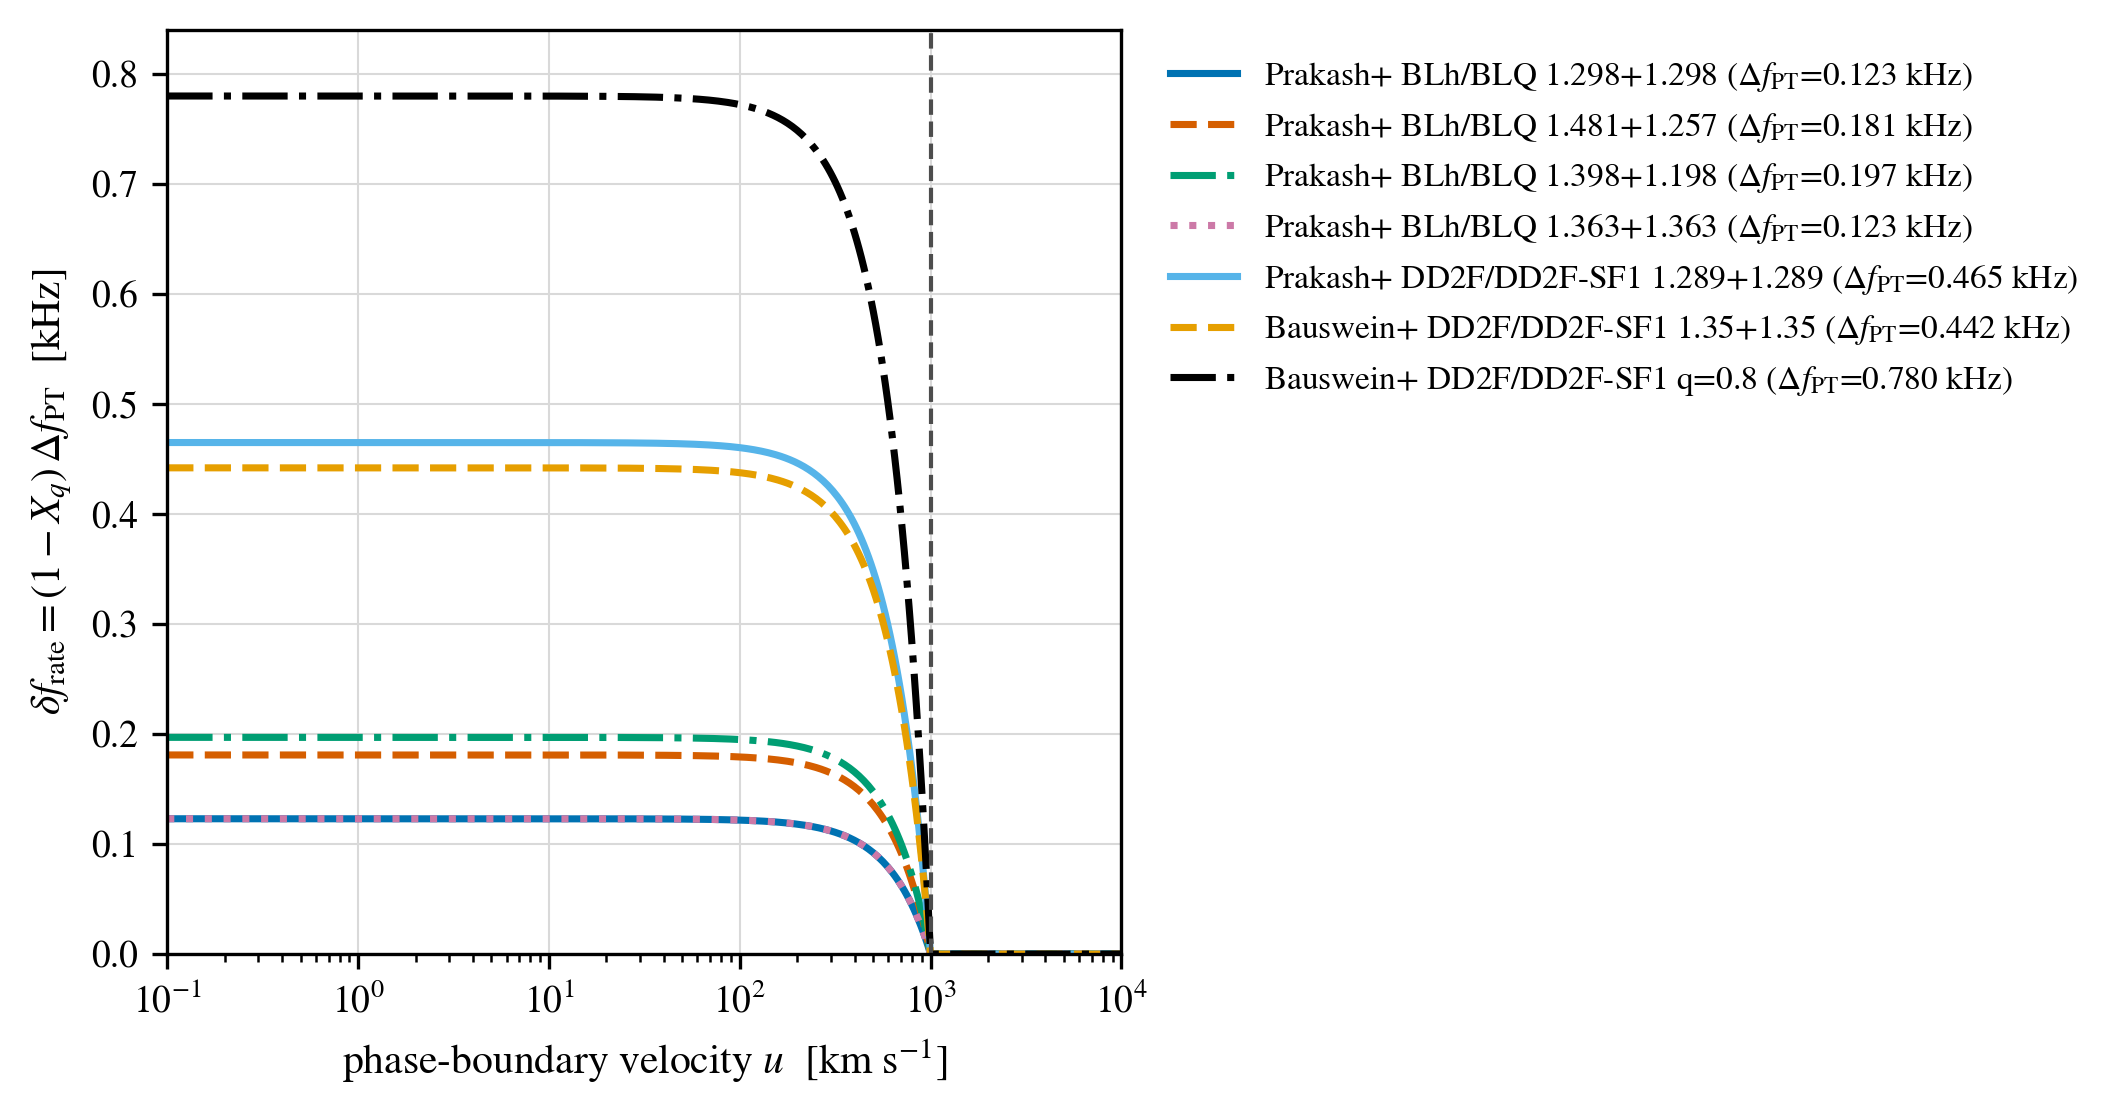

wrote figs/fig3_delta_f_rate_vs_u.pdf/.png


In [4]:
# Tunable plotting parameters
FIGURE_SIZE = (7.0, 3.6)
DPI = 300
FONT_FAMILY = "STIXGeneral"
MATH_FONTSET = "stix"
AXIS_LABEL_FONT_SIZE = 10
TICK_LABEL_FONT_SIZE = 9
LEGEND_FONT_SIZE = 8
LINE_WIDTH = 1.7
VLINE_COLOR = "0.3"
VLINE_STYLE = "--"
VLINE_WIDTH = 1.0
GRID_COLOR = "0.85"
GRID_LINE_WIDTH = 0.5
X_LIMITS = (1.0e-1, 1.0e4)
Y_LIMITS = (0.0, 0.84)
X_SCALE = "log"
LEGEND_ANCHOR = (1.02, 1.0)
LEGEND_LOCATION = "upper left"
EXPORT_STEM = "figs/fig3_delta_f_rate_vs_u"

# Figure 3: finite-rate frequency deficit delta_f_rate = (1 - X_q) * Delta_f_PT
import matplotlib.pyplot as plt

RC = {"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET,
      "axes.labelsize": AXIS_LABEL_FONT_SIZE, "xtick.labelsize": TICK_LABEL_FONT_SIZE,
      "ytick.labelsize": TICK_LABEL_FONT_SIZE, "legend.fontsize": LEGEND_FONT_SIZE}

with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=DPI)
    for (src, eos, masses, f_N, f_inf), color, style in zip(CASES, CASE_COLORS, CASE_STYLES):
        deficit = (1.0 - X_q_of_u(U_GRID_KM_S)) * (f_inf - f_N)
        ax.plot(U_GRID_KM_S, deficit, style, color=color, lw=LINE_WIDTH,
                label=case_label(src, eos, masses, f_N, f_inf))
    ax.axvline(U_SAT_KM_S, color=VLINE_COLOR, ls=VLINE_STYLE, lw=VLINE_WIDTH)
    ax.set_xscale(X_SCALE)
    ax.set_xlim(*X_LIMITS); ax.set_ylim(*Y_LIMITS)
    ax.set_xlabel(r"phase-boundary velocity $u$  [km s$^{-1}$]")
    ax.set_ylabel(r"$\delta f_{\rm rate}=(1-X_q)\,\Delta f_{\rm PT}$  [kHz]")
    ax.grid(True, which="major", color=GRID_COLOR, lw=GRID_LINE_WIDTH)
    ax.legend(loc=LEGEND_LOCATION, bbox_to_anchor=LEGEND_ANCHOR, frameon=False)
    fig.tight_layout(pad=0.3)
    fig.savefig(EXPORT_STEM + ".pdf", bbox_inches="tight")
    fig.savefig(EXPORT_STEM + ".png", bbox_inches="tight")
    plt.show()
print(f"wrote {EXPORT_STEM}.pdf/.png")


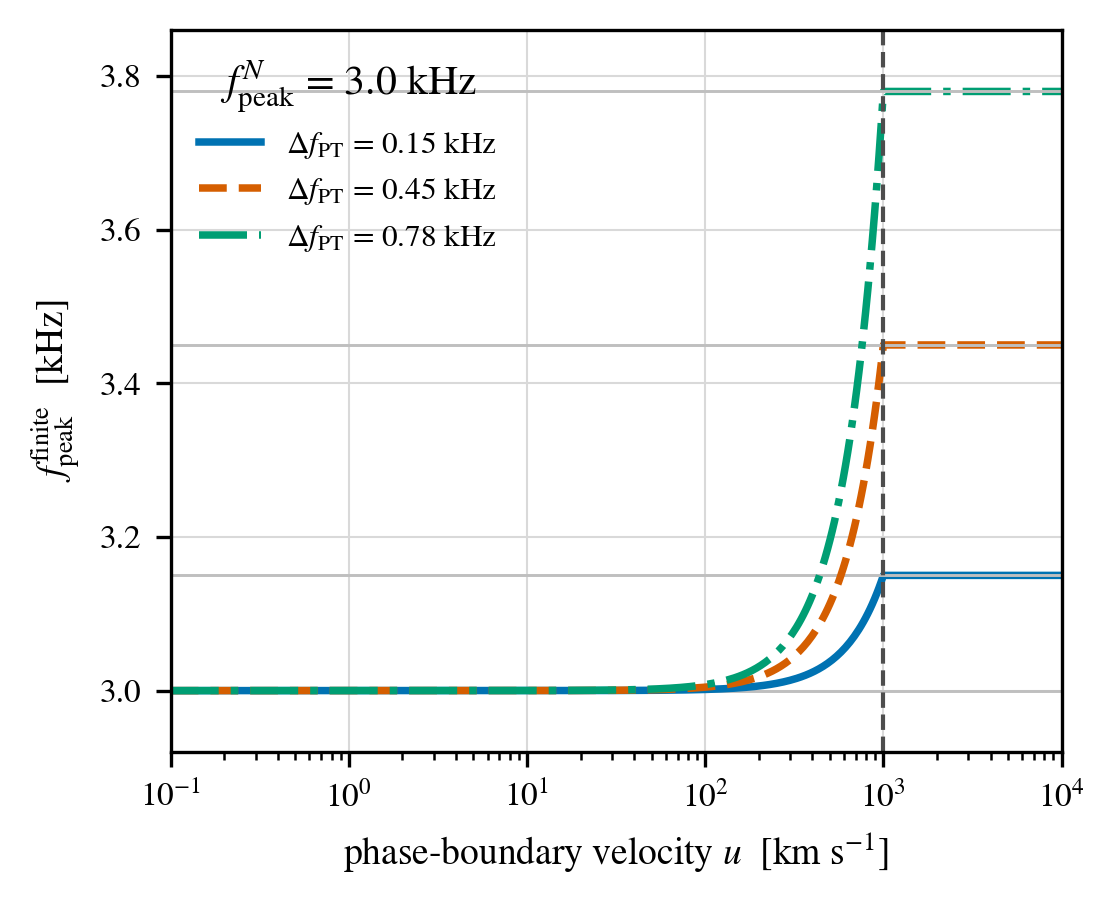

wrote figs/fig4_controlled_DeltafPT.pdf/.png


In [5]:
# Tunable plotting parameters
FIGURE_SIZE = (3.6, 2.9)
DPI = 300
FONT_FAMILY = "STIXGeneral"
MATH_FONTSET = "stix"
AXIS_LABEL_FONT_SIZE = 9
TICK_LABEL_FONT_SIZE = 8
LEGEND_FONT_SIZE = 7.5
LINE_WIDTH = 1.8
BENCHMARK_COLORS = ["#0072B2", "#D55E00", "#009E73"]
BENCHMARK_STYLES = ["-", "--", "-."]
BASELINE_F_N_KHZ = 3.0
BENCHMARK_DF_PT_KHZ = [0.15, 0.45, 0.78]
HLINE_COLOR = "0.75"
HLINE_WIDTH = 0.7
VLINE_COLOR = "0.3"
VLINE_STYLE = "--"
VLINE_WIDTH = 1.0
GRID_COLOR = "0.85"
GRID_LINE_WIDTH = 0.5
X_LIMITS = (1.0e-1, 1.0e4)
Y_LIMITS = (2.92, 3.86)
X_SCALE = "log"
LEGEND_LOCATION = "upper left"
EXPORT_STEM = "figs/fig4_controlled_DeltafPT"

# Figure 4: controlled comparison at fixed baseline f_peak_N = 3.0 kHz,
# f_peak_inf = f_peak_N + Delta_f_PT for benchmark Delta_f_PT values
import matplotlib.pyplot as plt

RC = {"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET,
      "axes.labelsize": AXIS_LABEL_FONT_SIZE, "xtick.labelsize": TICK_LABEL_FONT_SIZE,
      "ytick.labelsize": TICK_LABEL_FONT_SIZE, "legend.fontsize": LEGEND_FONT_SIZE}

with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=DPI)
    ax.axhline(BASELINE_F_N_KHZ, color=HLINE_COLOR, lw=HLINE_WIDTH)
    for df_pt, color, style in zip(BENCHMARK_DF_PT_KHZ, BENCHMARK_COLORS, BENCHMARK_STYLES):
        f_inf = BASELINE_F_N_KHZ + df_pt
        ax.plot(U_GRID_KM_S, f_finite_kHz(U_GRID_KM_S, BASELINE_F_N_KHZ, f_inf), style,
                color=color, lw=LINE_WIDTH,
                label=f"$\\Delta f_{{\\rm PT}}$ = {df_pt:.2f} kHz")
        ax.axhline(f_inf, color=HLINE_COLOR, lw=HLINE_WIDTH)
    ax.axvline(U_SAT_KM_S, color=VLINE_COLOR, ls=VLINE_STYLE, lw=VLINE_WIDTH)
    ax.set_xscale(X_SCALE)
    ax.set_xlim(*X_LIMITS); ax.set_ylim(*Y_LIMITS)
    ax.set_xlabel(r"phase-boundary velocity $u$  [km s$^{-1}$]")
    ax.set_ylabel(r"$f_{\rm peak}^{\rm finite}$  [kHz]")
    ax.grid(True, which="major", color=GRID_COLOR, lw=GRID_LINE_WIDTH)
    ax.legend(loc=LEGEND_LOCATION, frameon=False,
              title=f"$f_{{\\rm peak}}^{{N}}$ = {BASELINE_F_N_KHZ:.1f} kHz")
    fig.tight_layout(pad=0.3)
    fig.savefig(EXPORT_STEM + ".pdf"); fig.savefig(EXPORT_STEM + ".png")
    plt.show()
print(f"wrote {EXPORT_STEM}.pdf/.png")


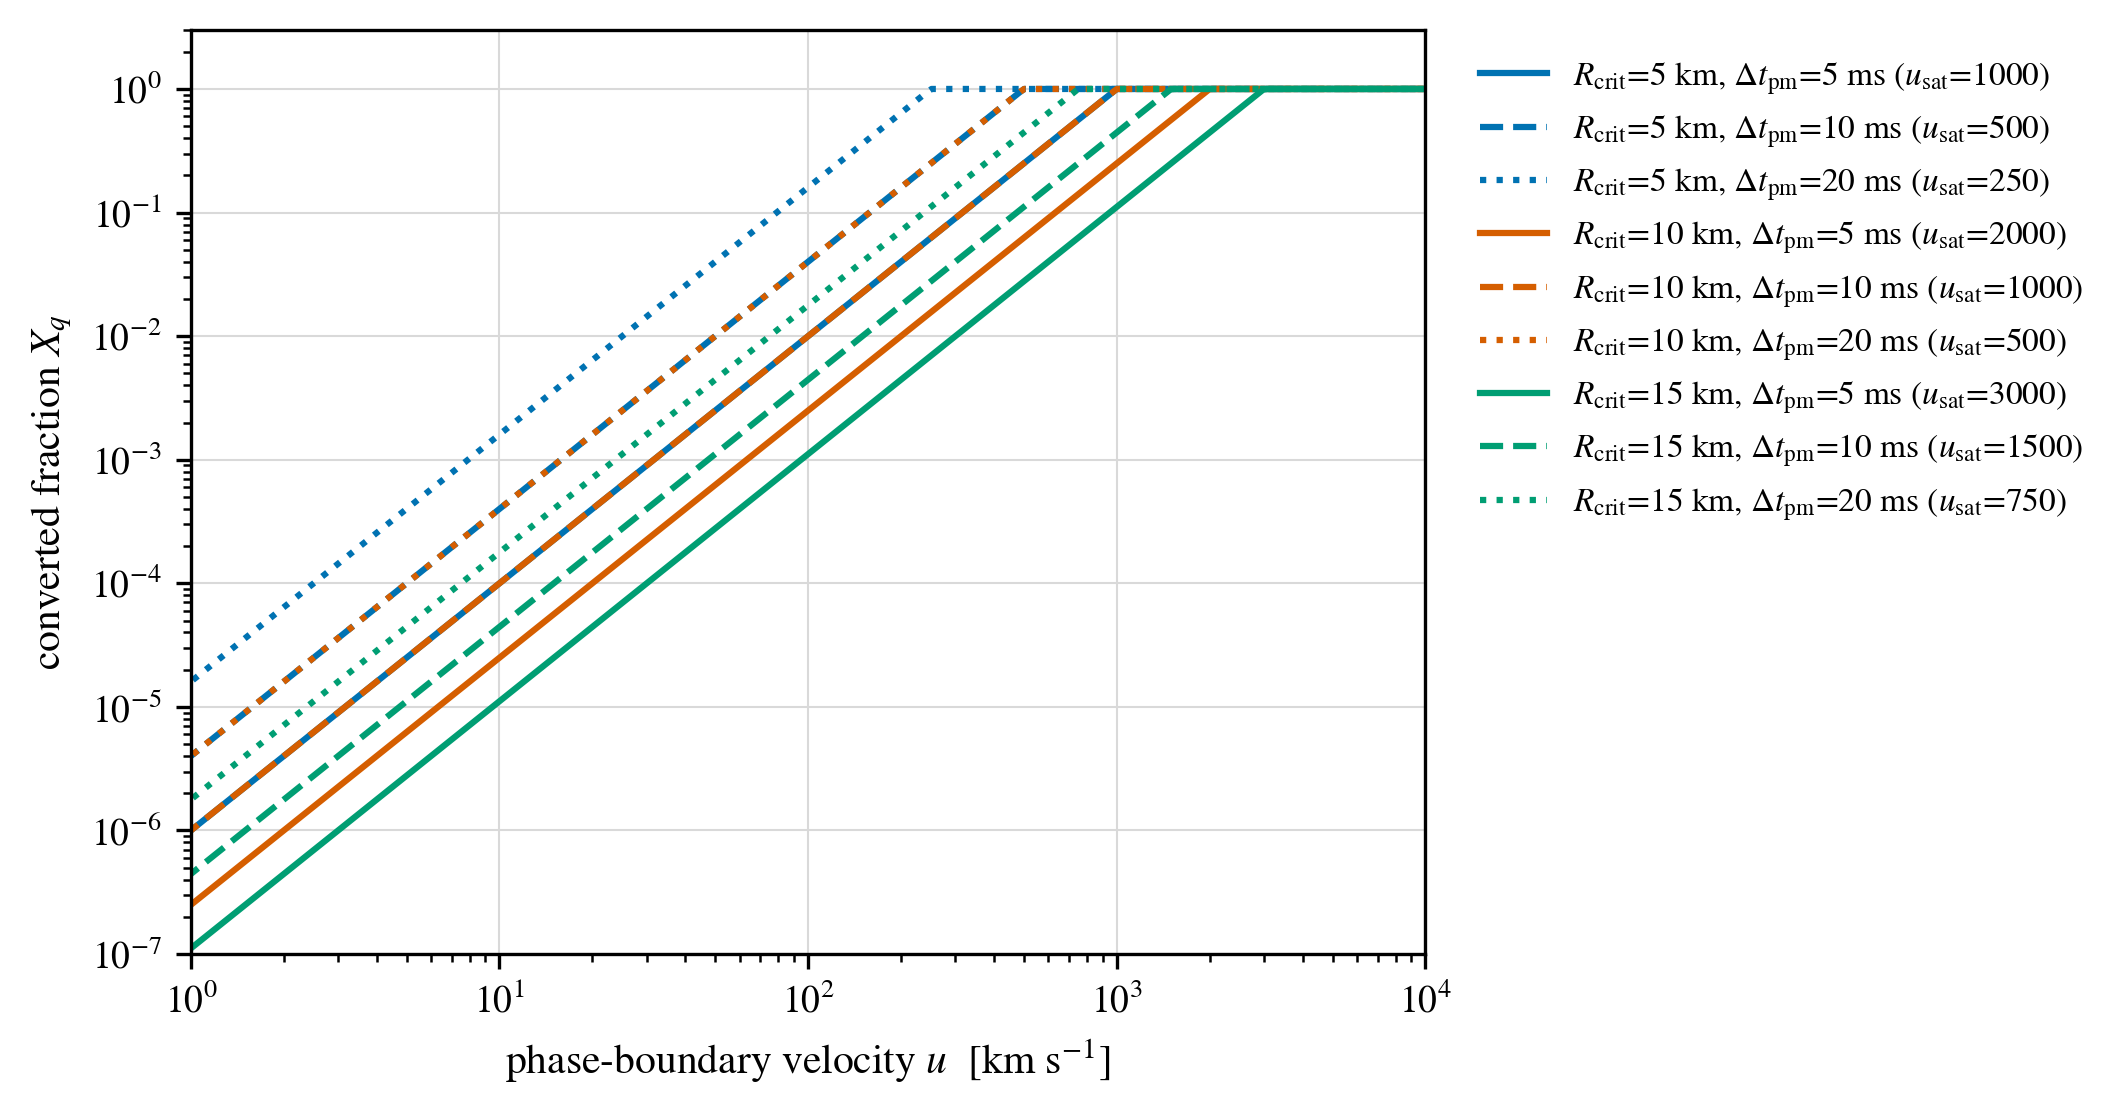

wrote figs/fig5_sensitivity_usat.pdf/.png


In [6]:
# Tunable plotting parameters
FIGURE_SIZE = (7.0, 3.6)
DPI = 300
FONT_FAMILY = "STIXGeneral"
MATH_FONTSET = "stix"
AXIS_LABEL_FONT_SIZE = 10
TICK_LABEL_FONT_SIZE = 9
LEGEND_FONT_SIZE = 8
LINE_WIDTH = 1.5
SENS_R_CRIT_KM = [5.0, 10.0, 15.0]
SENS_DT_PM_MS = [5.0, 10.0, 20.0]
SENS_COLORS = ["#0072B2", "#D55E00", "#009E73"]      # color = R_crit
SENS_STYLES = ["-", "--", ":"]                        # linestyle = Delta_t_pm
GRID_COLOR = "0.85"
GRID_LINE_WIDTH = 0.5
X_LIMITS = (1.0e0, 1.0e4)
Y_LIMITS = (1.0e-7, 3.0)
X_SCALE = "log"
Y_SCALE = "log"
LEGEND_ANCHOR = (1.02, 1.0)
LEGEND_LOCATION = "upper left"
EXPORT_STEM = "figs/fig5_sensitivity_usat"

# Figure 5 (sensitivity): X_q(u) for Delta_t_pm = 5/10/20 ms and R_crit = 5/10/15 km.
# u_sat = R_crit/Delta_t_pm shifts horizontally; the shape is a function of u/u_sat only.
import matplotlib.pyplot as plt

RC = {"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET,
      "axes.labelsize": AXIS_LABEL_FONT_SIZE, "xtick.labelsize": TICK_LABEL_FONT_SIZE,
      "ytick.labelsize": TICK_LABEL_FONT_SIZE, "legend.fontsize": LEGEND_FONT_SIZE}

with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=DPI)
    for r_km, color in zip(SENS_R_CRIT_KM, SENS_COLORS):
        for dt_ms, style in zip(SENS_DT_PM_MS, SENS_STYLES):
            u_sat = r_km / (dt_ms * 1.0e-3)
            ax.plot(U_GRID_KM_S, X_q_of_u(U_GRID_KM_S, dt_pm_ms=dt_ms, r_crit_km=r_km),
                    style, color=color, lw=LINE_WIDTH,
                    label=(f"$R_{{\\rm crit}}$={r_km:.0f} km, "
                           f"$\\Delta t_{{\\rm pm}}$={dt_ms:.0f} ms "
                           f"($u_{{\\rm sat}}$={u_sat:.0f})"))
    ax.set_xscale(X_SCALE); ax.set_yscale(Y_SCALE)
    ax.set_xlim(*X_LIMITS); ax.set_ylim(*Y_LIMITS)
    ax.set_xlabel(r"phase-boundary velocity $u$  [km s$^{-1}$]")
    ax.set_ylabel(r"converted fraction $X_q$")
    ax.grid(True, which="major", color=GRID_COLOR, lw=GRID_LINE_WIDTH)
    ax.legend(loc=LEGEND_LOCATION, bbox_to_anchor=LEGEND_ANCHOR, frameon=False, ncol=1)
    fig.tight_layout(pad=0.3)
    fig.savefig(EXPORT_STEM + ".pdf", bbox_inches="tight")
    fig.savefig(EXPORT_STEM + ".png", bbox_inches="tight")
    plt.show()
print(f"wrote {EXPORT_STEM}.pdf/.png")
